# Practice Problems - Worked Solutions

Twelve short, self-checking exercises covering Chapters 3-10. Each one has a bit of physics behind it and asks for a single number (or a few).

**How to use this notebook**
1. Run the first code cell - it defines `check(problem, answer)`.
2. For each problem, replace `answer = None` with your own code that computes the answer. **Don't type the number in by hand - compute it!**
3. Run the `check(...)` cell: you'll see ✅ if you're within tolerance, ❌ if not, and ⏳ if you haven't attempted it yet.

**This is the solutions notebook.** Every problem below is solved in full - compare with your own attempt in `practice-problems.ipynb`.

| # | Topic | Chapter |
| :-: | :--- | :-: |
| 1 | Wien's law in frequency form | 3 (Newton-Raphson) |
| 2 | How deep does a floating ball sink? | 3 (bisection) |
| 3 | A Gaussian moment integral | 4 (Simpson + substitution) |
| 4 | Gravity on the Moon from video data | 4 (finite differences) |
| 5 | Falling with air resistance | 5 (RK4 / events) |
| 6 | A pendulum released at 90° | 5 (Verlet / RK4) |
| 7 | Mesh currents in a circuit | 6 (Gaussian elimination) |
| 8 | The lowest mode of a chain of masses | 6 (inverse iteration) |
| 9 | Cooling of a rod | 7 (FTCS) |
| 10 | Find the hidden tone | 8 (FFT) |
| 11 | RC discharge: fitting a lifetime | 9 (curve fitting) |
| 12 | The Steinmetz solid | 10 (Monte Carlo) |

In [1]:
# Run this cell first.
import numpy as np
import matplotlib.pyplot as plt

_REFERENCE = {   # problem: (reference value, tolerance, 'rel' or 'abs')
    1: (2.82143937212, 1e-8, 'rel'),
    2: (1.13413784570, 1e-6, 'rel'),
    3: (0.44311346273, 1e-6, 'rel'),
    4: (-1.62, 1e-3, 'rel'),
    5: (5.30987470485, 1e-5, 'rel'),
    6: (1.18034059902, 1e-4, 'rel'),
    7: ([0.53164557, 0.13924051, 0.01265823], 1e-6, 'abs'),
    8: (0.51763809021, 1e-6, 'rel'),
    9: (0.37270783885, 2e-3, 'abs'),
    10: (37.0, 0.5, 'abs'),
    11: (2.47, 0.05, 'abs'),
    12: (4.68629150102, 0.05, 'abs'),
}

def check(problem, answer):
    if answer is None:
        print(f'⏳ Problem {problem}: not attempted yet')
        return
    ref, tol, kind = _REFERENCE[problem]
    ref, ans = np.asarray(ref, float), np.asarray(answer, float)
    if ans.shape != ref.shape:
        print(f'❌ Problem {problem}: expected an answer of shape {ref.shape}, got {ans.shape}')
        return
    err = np.max(np.abs(ans - ref)) if kind == 'abs' else np.max(np.abs(ans/ref - 1))
    if err <= tol:
        print(f'✅ Problem {problem}: correct! ({kind} error {err:.1e})')
    else:
        print(f'❌ Problem {problem}: not quite - your answer is {np.round(ans, 6)}. Keep going!')

---
## Problem 1 - Wien's law in frequency form *(Chapter 3)*
If you maximise Planck's law per unit **frequency** instead of per unit wavelength (as in the Optics applications notebook), the peak occurs at $x = h\nu/k_BT$ satisfying

$$3\left(1 - e^{-x}\right) = x, \qquad x > 0.$$

Use **Newton-Raphson** (write it yourself!) starting from $x_0=3$ to find $x$ to at least 10 significant figures.

In [2]:
f = lambda x: 3*(1 - np.exp(-x)) - x
df = lambda x: 3*np.exp(-x) - 1
x = 3.0
for _ in range(50):
    step = f(x)/df(x)
    x -= step
    if abs(step) < 1e-14:
        break
answer = x
print(f'x = {answer:.12f}  ->  the peak frequency is nu_max = {answer:.4f} k_B T / h')
check(1, answer)

x = 2.821439372122  ->  the peak frequency is nu_max = 2.8214 k_B T / h
✅ Problem 1: correct! (rel error 7.4e-13)


## Problem 2 - How deep does a floating ball sink? *(Chapter 3)*
A solid sphere of radius $R$ and relative density $s=0.6$ floats in water. By Archimedes, the submerged depth $h$ (in units of $R$) satisfies

$$h^3 - 3h^2 + 4s = 0, \qquad 0 < h < 2.$$

Use **bisection** on $[0, 2]$ to find $h$ to $10^{-10}$.

In [3]:
g = lambda h: h**3 - 3*h**2 + 4*0.6
a, b = 0.0, 2.0
while b - a > 1e-12:
    m = 0.5*(a + b)
    if np.sign(g(m)) == np.sign(g(a)):
        a = m
    else:
        b = m
answer = 0.5*(a + b)
print(f'h = {answer:.10f} R  (more than half submerged, as expected for s > 0.5)')
check(2, answer)

h = 1.1341378457 R  (more than half submerged, as expected for s > 0.5)
✅ Problem 2: correct! (rel error 3.6e-12)


## Problem 3 - A Gaussian moment integral *(Chapter 4)*
The mean kinetic energy of a particle in a harmonic trap involves

$$I = \int_0^\infty x^2e^{-x^2}\,dx.$$

Map the infinite range onto $[0,1)$ with $x = t/(1-t)$ and evaluate the integral with **your own composite Simpson's rule** using 1000 strips. (Hint: the transformed integrand at $t=1$ is $0$ - but you'll need to treat that point carefully to avoid dividing by zero.)

In [4]:
def integrand(t):
    t = np.asarray(t, float)
    out = np.zeros_like(t)
    ok = t < 1
    x = t[ok]/(1 - t[ok])
    out[ok] = x**2*np.exp(-x**2)/(1 - t[ok])**2
    return out                                  # the limit at t = 1 is 0

N = 1000
t = np.linspace(0, 1, N + 1)
y = integrand(t)
h = 1/N
answer = h/3*(y[0] + 4*y[1:-1:2].sum() + 2*y[2:-1:2].sum() + y[-1])
print(f'I = {answer:.12f}, exact sqrt(pi)/4 = {np.sqrt(np.pi)/4:.12f}')
check(3, answer)

I = 0.443113462726, exact sqrt(pi)/4 = 0.443113462726
✅ Problem 3: correct! (rel error 8.5e-12)


## Problem 4 - Gravity on the Moon from video data *(Chapter 4)*
An astronaut throws a rock upwards and a video tracks its height every 0.1 s (data below). Estimate the gravitational acceleration from the data using the **central second-difference** formula $\frac{y_{i+1}-2y_i+y_{i-1}}{\Delta t^2}$ at every interior point, then average. (Your answer is negative because it points down.)

In [5]:
t_data = np.linspace(0, 3, 31)
y_data = 1.5 + 4*t_data - 0.81*t_data**2          # height in metres (no noise - lucky astronaut)

In [6]:
dt = t_data[1] - t_data[0]
acc = (y_data[2:] - 2*y_data[1:-1] + y_data[:-2])/dt**2
answer = acc.mean()
print(f'g_moon ≈ {answer:.4f} m/s^2')
# Note: np.gradient(np.gradient(y)) is *not* the same - it uses one-sided differences at the ends,
# which spoil the average. Try it!
check(4, answer)

g_moon ≈ -1.6200 m/s^2
✅ Problem 4: correct! (rel error 4.4e-16)


## Problem 5 - Falling with air resistance *(Chapter 5)*
A small object is dropped from rest from a height of 100 m. With linear drag its velocity obeys $\dot v = g - kv$ (taking down as positive) with $g = 9.81$ m/s² and $k=0.2$ s⁻¹. How long does it take to hit the ground?

Solve the system $\dot y = v,\ \dot v = g - kv$ with **RK4** (your own, $h=10^{-3}$ s) and find the landing time by linear interpolation between the last two steps - or use `solve_ivp` with an event. *(Bonus: there is an analytic solution - find the time with Newton-Raphson as a check.)*

In [7]:
g, k = 9.81, 0.2
f = lambda s: np.array([s[1], g - k*s[1]])
s, t, h = np.array([0.0, 0.0]), 0.0, 1e-3
while s[0] < 100:
    k1 = f(s); k2 = f(s + h/2*k1); k3 = f(s + h/2*k2); k4 = f(s + h*k3)
    s_new = s + h/6*(k1 + 2*k2 + 2*k3 + k4)
    if s_new[0] >= 100:                         # interpolate to the exact crossing
        answer = t + h*(100 - s[0])/(s_new[0] - s[0])
    s, t = s_new, t + h
print(f'lands after {answer:.6f} s (free fall would take {np.sqrt(200/g):.3f} s)')
check(5, answer)

lands after 5.309875 s (free fall would take 4.515 s)
✅ Problem 5: correct! (rel error 1.1e-09)


## Problem 6 - A pendulum released at 90° *(Chapter 5)*
A pendulum obeys $\ddot\theta = -\sin\theta$ (units with $g/L=1$, so the small-angle period is $T_0 = 2\pi$). It is released from rest at $\theta_0=90°$. Find the ratio $T/T_0$ by simulation: integrate with **velocity Verlet** ($h = 10^{-4}$) until $\theta$ first crosses zero, which happens at $T/4$.

In [8]:
theta, omega, t, h = np.pi/2, 0.0, 0.0, 1e-4
a = -np.sin(theta)
while True:
    omega_half = omega + 0.5*h*a
    theta_new = theta + h*omega_half
    if theta_new <= 0:                          # interpolate the zero crossing
        t_quarter = t + h*theta/(theta - theta_new)
        break
    theta, t = theta_new, t + h
    a = -np.sin(theta)
    omega = omega_half + 0.5*h*a
answer = 4*t_quarter/(2*np.pi)
print(f'T/T0 = {answer:.6f}: the 90° pendulum is {100*(answer - 1):.1f}% slower than the small-angle formula')
check(6, answer)

T/T0 = 1.180341: the 90° pendulum is 18.0% slower than the small-angle formula
✅ Problem 6: correct! (rel error 2.9e-10)


## Problem 7 - Mesh currents in a circuit *(Chapter 6)*
Kirchhoff's voltage law for a three-loop circuit gives (currents in A, resistances in Ω, voltages in V)

$$\begin{pmatrix}10 & -2 & -3\\ -2 & 8 & -4\\ -3 & -4 & 12\end{pmatrix}\begin{pmatrix}I_1\\I_2\\I_3\end{pmatrix} = \begin{pmatrix}5\\0\\-2\end{pmatrix}.$$

Solve it with **your own Gaussian elimination with partial pivoting**, and give the answer as an array `[I1, I2, I3]`.

In [9]:
A = np.array([[10, -2, -3], [-2, 8, -4], [-3, -4, 12]], float)
b = np.array([5, 0, -2], float)
n = len(b)
for col in range(n - 1):
    p = col + np.argmax(np.abs(A[col:, col]))
    A[[col, p]], b[[col, p]] = A[[p, col]], b[[p, col]]
    for i in range(col + 1, n):
        m = A[i, col]/A[col, col]
        A[i, col:] -= m*A[col, col:]
        b[i] -= m*b[col]
x = np.zeros(n)
for i in range(n - 1, -1, -1):
    x[i] = (b[i] - A[i, i+1:] @ x[i+1:])/A[i, i]
answer = x
print('I =', np.round(answer, 6), 'A')
check(7, answer)

I = [0.531646 0.139241 0.012658] A
✅ Problem 7: correct! (abs error 3.7e-09)


## Problem 8 - The lowest mode of a chain of masses *(Chapter 6)*
Five equal masses $m=1$ are joined in a line by six identical springs $k=1$, with the ends fixed to walls. The squared normal-mode frequencies are the eigenvalues of the $5\times5$ tridiagonal matrix with $2$ on the diagonal and $-1$ on the off-diagonals. Find the **lowest angular frequency** $\omega$ using **inverse iteration** (power iteration on $K^{-1}$ - use a linear solve, not `inv`).

In [10]:
K = 2*np.eye(5) - np.eye(5, k=1) - np.eye(5, k=-1)
v = np.ones(5)
lam_old = 0
for _ in range(500):
    v = np.linalg.solve(K, v)
    v /= np.linalg.norm(v)
    lam = v @ K @ v
    if abs(lam - lam_old) < 1e-15:
        break
    lam_old = lam
answer = np.sqrt(lam)
print(f'lowest omega = {answer:.10f}, analytic 2 sin(pi/12) = {2*np.sin(np.pi/12):.10f}')
check(8, answer)

lowest omega = 0.5176380902, analytic 2 sin(pi/12) = 0.5176380902
✅ Problem 8: correct! (rel error 9.6e-12)


## Problem 9 - Cooling of a rod *(Chapter 7)*
A rod of length 1 with ends held at zero obeys $u_t = u_{xx}$, with initial temperature $u(x,0)=\sin(\pi x)$. Use **FTCS** with 51 grid points and $r = \Delta t/\Delta x^2 = 0.25$ to find the temperature at the centre at $t=0.1$.

In [11]:
x = np.linspace(0, 1, 51)
dx = x[1] - x[0]
r = 0.25
dt = r*dx**2
u = np.sin(np.pi*x)
for _ in range(int(round(0.1/dt))):
    u[1:-1] += r*(u[2:] - 2*u[1:-1] + u[:-2])
answer = u[25]
print(f'u(0.5, 0.1) = {answer:.6f}, exact exp(-pi^2 t) = {np.exp(-np.pi**2*0.1):.6f}')
check(9, answer)

u(0.5, 0.1) = 0.372647, exact exp(-pi^2 t) = 0.372708
✅ Problem 9: correct! (abs error 6.1e-05)


## Problem 10 - Find the hidden tone *(Chapter 8)*
The signal below contains two pure tones buried in noise that is much louder than either of them. Use the **FFT** to find the frequency (in Hz) of the **strongest** tone.

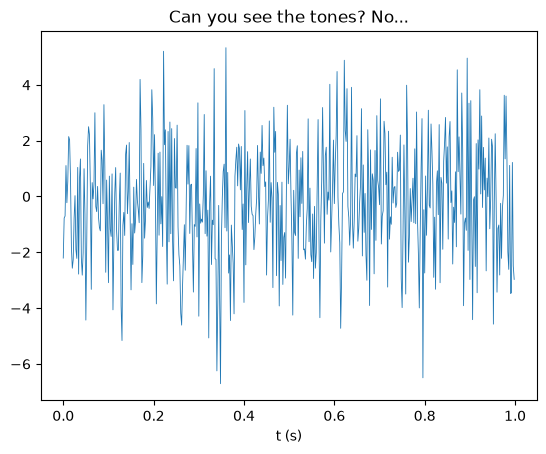

In [12]:
rng = np.random.default_rng(10)
fs = 500
t_sig = np.arange(0, 4, 1/fs)
signal = 0.7*np.sin(2*np.pi*37*t_sig) + 0.4*np.sin(2*np.pi*91*t_sig) + 2*rng.normal(size=t_sig.size)
plt.plot(t_sig[:500], signal[:500], lw=0.6); plt.xlabel('t (s)'); plt.title('Can you see the tones? No...'); plt.show()

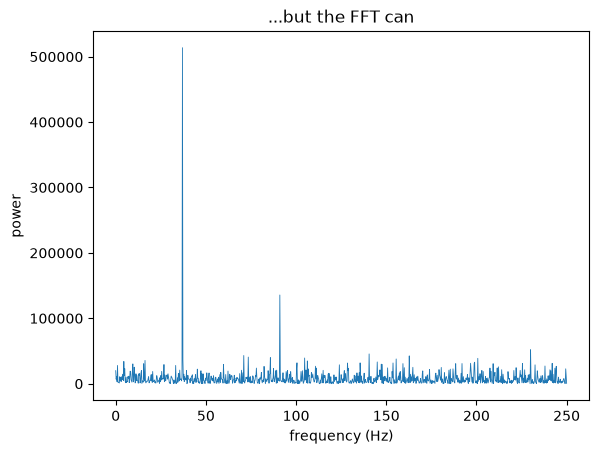

strongest tone at 37.0 Hz
✅ Problem 10: correct! (abs error 0.0e+00)


In [13]:
P = np.abs(np.fft.rfft(signal))**2
nu = np.fft.rfftfreq(signal.size, 1/fs)
answer = nu[1:][np.argmax(P[1:])]               # skip the zero-frequency bin
plt.plot(nu, P, lw=0.6); plt.xlabel('frequency (Hz)'); plt.ylabel('power'); plt.title('...but the FFT can'); plt.show()
print(f'strongest tone at {answer:.1f} Hz')
check(10, answer)

## Problem 11 - RC discharge: fitting a lifetime *(Chapter 9)*
A capacitor discharges through a resistor, $V(t) = V_0e^{-t/\tau}$. The (noisy) voltmeter readings are below; each has an uncertainty of 0.05 V. Fit for $\tau$ using `scipy.optimize.curve_fit` and also print its uncertainty and the reduced $\chi^2$.

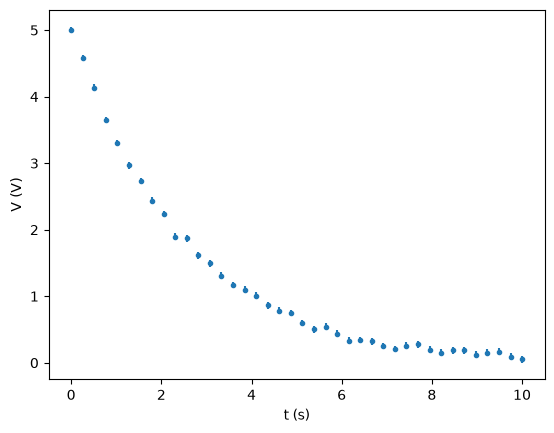

In [14]:
rng = np.random.default_rng(11)
t_rc = np.linspace(0, 10, 40)
V_rc = 5*np.exp(-t_rc/2.5) + rng.normal(0, 0.05, t_rc.size)
plt.errorbar(t_rc, V_rc, 0.05, fmt='o', ms=3); plt.xlabel('t (s)'); plt.ylabel('V (V)'); plt.show()

In [15]:
from scipy.optimize import curve_fit
model = lambda t, V0, tau: V0*np.exp(-t/tau)
sigma = 0.05*np.ones_like(t_rc)
popt, pcov = curve_fit(model, t_rc, V_rc, p0=[4, 1], sigma=sigma, absolute_sigma=True)
chi2_nu = np.sum(((V_rc - model(t_rc, *popt))/sigma)**2)/(len(t_rc) - 2)
answer = popt[1]
print(f'tau = {popt[1]:.3f} ± {np.sqrt(pcov[1, 1]):.3f} s,  V0 = {popt[0]:.3f} V,  reduced chi^2 = {chi2_nu:.2f}')
check(11, answer)

tau = 2.473 ± 0.021 s,  V0 = 5.038 V,  reduced chi^2 = 0.71
✅ Problem 11: correct! (abs error 3.5e-03)


## Problem 12 - The Steinmetz solid *(Chapter 10)*
Three cylinders of radius 1 along the $x$, $y$ and $z$ axes intersect in a curved solid (the *tricylinder Steinmetz solid*): the points with $x^2+y^2\le1$, $y^2+z^2\le1$ **and** $x^2+z^2\le1$. Estimate its volume with **Monte Carlo** by throwing at least $10^6$ random points into the cube $[-1,1]^3$. Print your error estimate too.

In [16]:
rng = np.random.default_rng(12)
N = 2_000_000
p = rng.uniform(-1, 1, size=(N, 3))
x, y, z = p.T
inside = (x**2 + y**2 <= 1) & (y**2 + z**2 <= 1) & (x**2 + z**2 <= 1)
answer = 8*inside.mean()
err = 8*inside.std()/np.sqrt(N)
print(f'V ≈ {answer:.4f} ± {err:.4f}   (exact 8(2 - sqrt 2) = {8*(2 - np.sqrt(2)):.4f})')
check(12, answer)

V ≈ 4.6838 ± 0.0028   (exact 8(2 - sqrt 2) = 4.6863)
✅ Problem 12: correct! (abs error 2.5e-03)


<details>
<summary>🥚 Secret problem</summary>

## Problem 13 - Secret problem *(Chapter 3)*
A deliberate bonus, not part of the main set. In single-slit diffraction (Applications III, section A3.2), the intensity is $I\propto\left(\frac{\sin\beta}{\beta}\right)^2$. Its secondary maxima are **not** halfway between the zeros: setting $dI/d\beta=0$ gives the transcendental equation

$$\tan\beta = \beta.$$

Find the first secondary maximum: the smallest **positive** root of $\tan\beta = \beta$ other than $\beta=0$. Careful, $\tan$ has poles. Bracket your root between two of them. The checker only accepts an answer correct to 6 decimal places, and it doesn't reveal the answer.
</details>

In [17]:
import numpy as np
from scipy.optimize import brentq
# tan has poles at pi/2, 3pi/2, ... so the first nonzero root lies in (pi, 3pi/2)
g = lambda b: np.tan(b) - b
answer = brentq(g, np.pi + 1e-9, 1.5*np.pi - 1e-9)
print(f'beta = {answer:.10f}')

# The secret checker compares a fingerprint (hash) of your answer, so it can't give the answer away.
import hashlib
if answer is None:
    print('⏳ Secret problem: not attempted yet')
else:
    assert hashlib.sha256(f'{answer:.6f}'.encode()).hexdigest() == '4219c0dc7bb72c873730efbc908b3305d50a970080039704d04e74dbb202882d', 'Not quite - keep going!'
    print('✅ Secret problem solved. The first side lobe of a slit is at beta = %.6f, not 3*pi/2 = %.6f.' % (answer, 1.5*3.141592653589793))

beta = 4.4934094579
✅ Secret problem solved. The first side lobe of a slit is at beta = 4.493409, not 3*pi/2 = 4.712389.


---
### Finished?
Try going further: each problem can be extended. Measure the order of convergence of your Simpson integral in Problem 3, swap Verlet for Euler in Problem 6 and see how wrong it gets, push $r$ above $0.5$ in Problem 9, or replace Problem 12's uniform sampling with something smarter. Then head to the `Applications` folder for bigger projects.